# 탱크별 cool 동반 연속 횟수 — 일별 집계 (2026-09-10 ~ 10-14)

**질문:** 9/10 부터 지금까지, 날마다 exchanger 사이클에 cool 이 같이 켜진 경우가
몇 번 연속으로 나왔는가. (예: 1회 단발 30개, 2회 연속 5개, 3회 연속 1개 …) — 8개 탱크 전부.

## 정의 — 기존 전처리/모델을 그대로 쓴다

| 항목 | 정의 | 출처 |
|---|---|---|
| exchanger 사이클 | 원시 ON 구간을 OFF < 90초면 이어붙인 '논리적 사이클' | `Tank_Preprocess.merge_cycles` |
| cool 동반 | 사이클 구간 동안 cool 이 한 번이라도 1 (시작 시점 값 포함) | `Tank_Preprocess.flag_cool` |
| 연속(run) | cool 동반 사이클이 끊기지 않고 이어진 개수 | `Tank_Diagnosis_Model.check_consecutive_cool` 와 같은 방식 |
| **일별 집계** | 사이클 시작 날짜 기준. **run 은 자정에서 끊는다** | 이 노트북에서 추가 |

- "1회" = 앞뒤 사이클에는 cool 이 없고 그 사이클만 cool 동반(단발).
- 규칙 ③ 은 자정 리셋이 없다. 자정에서 끊어서 달라지는 run 은 탱크당 1~4개뿐이다(아래 3장).

## 데이터

| 항목 | 값 |
|---|---|
| 태그 | 탱크별 `... Exchanger SOL`, `... Cooling SOL` 2개 (`Tank_Preprocess.TANKS`) |
| 수집 | InfluxDB `plc_line2`, **탱크 하나씩** (`LogExtractor.get_data`) |
| 구간 | 2026-09-09 10:00 ~ 2026-10-14 11:00 KST — 9/10 0시 경계의 사이클이 잘리지 않게 하루 앞당겨 받고, 집계는 9/10 부터 |
| 캐시 | `parkkt/cache/tank_exch_cool/{탱크}.pkl` (있으면 DB 를 다시 안 탄다) |

`extracted_csv` 캐시는 10/02 까지만 있어서 `Tank_Preprocess.load_signals()` 를 그대로 쓰면
10/02 이후가 빠진다. 그래서 여기서는 직접 받았다.

## 0. 준비

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

matplotlib.rcParams["font.family"] = "Malgun Gothic"
matplotlib.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 170)
pd.set_option("display.max_rows", 200)

PARKKT = os.getcwd() if os.path.basename(os.getcwd()) == "parkkt" else os.path.join(os.getcwd(), "parkkt")
ROOT = os.path.dirname(PARKKT)
sys.path.insert(0, PARKKT); sys.path.insert(0, ROOT)

import Tank_Preprocess as prep
import Tank_Diagnosis_Model as model

PULL_START, PULL_END = "2026-09-09 10:00:00", "2026-10-14 11:00:00"
DAY0 = pd.Timestamp("2026-09-10")
CACHE = os.path.join(PARKKT, "cache", "tank_exch_cool")
TANK_LIST = list(prep.TANKS)

In [2]:
def load_tank(tank):
    # exchanger / cool 원시 0-1 신호. 캐시가 없으면 InfluxDB 에서 이 탱크 태그 2개만 받는다.
    path = os.path.join(CACHE, f"{tank}.pkl")
    t = prep.TANKS[tank]
    if os.path.exists(path):
        df = pd.read_pickle(path)
    else:
        from Log_Extractor import LogExtractor
        ex = LogExtractor(env_path=os.path.join(ROOT, ".env"))
        df = ex.get_data(PULL_START, PULL_END, [t["exch"], t["cool"]])
        os.makedirs(CACHE, exist_ok=True)
        df.to_pickle(path)
    df = df[~df.index.duplicated(keep="last")].sort_index()
    return df[t["exch"]].dropna(), df[t["cool"]].dropna()


SIG = {tank: load_tank(tank) for tank in TANK_LIST}
for tank, (exch, cool) in SIG.items():
    print(f"{tank}  {len(exch):>7,}행   {exch.index.min():%m-%d %H:%M} ~ {exch.index.max():%m-%d %H:%M}")

P1   54,070행   09-09 10:03 ~ 10-14 10:56
P2   97,523행   09-09 10:03 ~ 10-14 10:56
P3   58,467행   09-09 10:03 ~ 10-14 10:56
P4  104,320행   09-09 10:03 ~ 10-14 10:56
P5   43,939행   09-09 10:03 ~ 10-14 10:56
I1   46,886행   09-09 10:03 ~ 10-14 10:56
I2   48,492행   09-09 10:03 ~ 10-14 10:56
I3   40,333행   09-09 10:03 ~ 10-14 10:57


## 1. 재현 확인 — 새로 받은 데이터가 기존 결과와 같은가

`Tank_Diagnosis_최종정리.ipynb` 의 P1 결과(9/09 ~ 10/02 12:35)는
사이클 1,254 · cool 동반 132 · 연속 {1회 110, 2회 8, 3회 2} 였다.
같은 구간을 잘라 같은 함수로 돌려서 같은 숫자가 나오면, 데이터 경로와 전처리가 동일하다는 뜻이다.

In [3]:
exch, cool = SIG["P1"]
end = "2026-10-02 12:35:27"
c = prep.flag_cool(prep.merge_cycles(exch.loc[:end]), cool.loc[:end])
_, r = model.check_consecutive_cool(c, n=10**9)
print(f"사이클 {len(c):,} · cool 동반 {int(c['cool_overlap'].sum())} · 연속 {r['run_len'].value_counts().sort_index().to_dict()}")

사이클 1,254 · cool 동반 132 · 연속 {1: 110, 2: 8, 3: 2}


## 2. 90초 병합 기준이 다른 탱크에도 맞는가

90초 기준은 P1 의 OFF 길이 분포(채터링 < 60초 / 진짜 OFF > 300초, 그 사이가 빔)로 정했다.
다른 탱크도 그런지 OFF 길이 분포를 같이 본다.

In [4]:
bins = [0, 5, 10, 20, 30, 45, 60, 75, 90, 120, 150, 200, 250, 300, 400, 600, 900, 1800, 3600, np.inf]
labels = [f"{int(a)}~{'' if b == np.inf else int(b)}" for a, b in zip(bins[:-1], bins[1:])]
gap_tbl = {}
for tank, (exch, _) in SIG.items():
    segs = prep.raw_segments(exch)
    g = pd.Series([(segs[i + 1][0] - segs[i][1]).total_seconds() for i in range(len(segs) - 1)])
    gap_tbl[tank] = pd.cut(g, bins, right=False, labels=labels).value_counts().sort_index()
gap_tbl = pd.DataFrame(gap_tbl)
gap_tbl.index.name = "OFF 길이(초)"
gap_tbl

,P1,P2,P3,P4,P5,I1,I2,I3
OFF 길이(초),,,,,,,,
0~5,17554,35003,20186,37038,5556,15624,12246,11000
5~10,616,2079,168,1569,45,50,1902,58
10~20,180,688,137,302,48,38,1077,35
20~30,54,140,79,59,28,23,534,16
30~45,12,57,109,54,24,16,435,6
45~60,4,35,94,47,32,6,134,11
60~75,2,42,27,56,56,5,100,6
75~90,1,31,3,70,149,4,95,9
90~120,2,86,0,210,1068,9,83,11


- **P1 · P3 · I1 · I3** — 60~300초가 거의 비어 있다. 90초 기준 문제없음.
- **P2** — 진짜 OFF 가 300~400초에 몰려 있지만 60~300초에 꼬리가 있다.
- **P4** — 진짜 OFF 자체가 150~250초로 짧다. 90~150초에도 수백 건.
- **P5** — 진짜 OFF 가 90~200초다. **90초 기준이 진짜 OFF 분포 한가운데를 자른다.**
- **I2** — 뚜렷한 빈 구간이 없다.

그래서 기준을 30 / 45 / 90 / 150 / 300초로 바꿔가며 연속 분포가 얼마나 변하는지 확인한다(3장 함수 사용).

## 3. 집계 함수

In [5]:
def runs_by_day(cyc):
    # cool 동반 run 을 사이클 시작 날짜별로 끊어서 센다.
    c = cyc.sort_values("cycle_start").reset_index(drop=True)
    c["day"] = c["cycle_start"].dt.normalize()
    out = []
    for day, g in c.groupby("day"):
        v = g["cool_overlap"].astype(bool).values
        run = 0
        for i, x in enumerate(v):
            run = run + 1 if x else 0
            if run and (i + 1 == len(v) or not v[i + 1]):
                out.append({"day": day, "run_len": run,
                            "start": g["cycle_start"].iloc[i - run + 1],
                            "end": g["cycle_end"].iloc[i]})
    return pd.DataFrame(out, columns=["day", "run_len", "start", "end"])


def analyze(tank, gap=prep.MERGE_GAP_SEC):
    exch, cool = SIG[tank]
    cyc = prep.flag_cool(prep.merge_cycles(exch, gap), cool)
    _, cont = model.check_consecutive_cool(cyc, n=10**9)      # 자정 리셋 없는 원래 방식
    cyc = cyc[cyc["cycle_start"] >= DAY0]
    cont = cont[cont["start_time"] >= DAY0] if len(cont) else cont
    runs = runs_by_day(cyc)
    days = cyc.groupby(cyc["cycle_start"].dt.normalize()).agg(
        사이클=("cool_overlap", "size"), cool동반=("cool_overlap", "sum"))
    days.index.name = "day"
    return {"cyc": cyc, "runs": runs, "days": days, "cont": cont}


BUCKETS = ["1", "2", "3", "4", "5", "6~9", "10~19", "20+"]
def bucket(n):
    return str(n) if n <= 5 else ("6~9" if n < 10 else ("10~19" if n < 20 else "20+"))


RES = {tank: analyze(tank) for tank in TANK_LIST}

### 자정에서 끊는 영향

일별로 보려고 run 을 자정에서 끊었다. 규칙 ③ (자정 리셋 없음) 과 run 개수가 얼마나 다른지.

In [6]:
pd.DataFrame([{
    "탱크": t,
    "run 수 (자정 끊음)": len(RES[t]["runs"]),
    "run 수 (규칙③ 방식)": len(RES[t]["cont"]),
    "최장 (자정 끊음)": int(RES[t]["runs"]["run_len"].max()),
    "최장 (규칙③ 방식)": int(RES[t]["cont"]["run_len"].max()) if len(RES[t]["cont"]) else None,
} for t in TANK_LIST]).set_index("탱크")

,run 수 (자정 끊음),run 수 (규칙③ 방식),최장 (자정 끊음),최장 (규칙③ 방식)
탱크,,,,
P1,205,202,3,3.0
P2,772,766,8,8.0
P3,98,97,2,3.0
P4,896,894,5,5.0
P5,165,140,117,117.0
I1,145,141,9,9.0
I2,28,0,67,NaN
I3,395,393,5,5.0


P1~P4 · I1 · I3 는 1~6개 차이로 사실상 같다. P5 는 밤을 건너 이어지는 긴 run 이 있어 25개 차이.
I2 는 규칙③ 방식으로는 **9/09 부터 지금까지 run 이 하나**다 (모든 사이클이 cool 동반 — 5장).

### 병합 기준(초)을 바꾸면

In [7]:
rows = []
for tank in TANK_LIST:
    for gap in (30, 45, 90, 150, 300):
        r = analyze(tank, gap)
        h = r["runs"]["run_len"].map(bucket).value_counts()
        rows.append({"탱크": tank, "병합기준": gap, "사이클": len(r["cyc"]),
                     "cool동반%": round(100 * r["cyc"]["cool_overlap"].mean(), 1),
                     **{b: int(h.get(b, 0)) for b in BUCKETS},
                     "최장": int(r["runs"]["run_len"].max())})
sens = pd.DataFrame(rows).set_index(["탱크", "병합기준"])
sens

사이클  cool동반%    1    2   3   4   5  6~9  10~19  20+   최장
탱크 병합기준                                                           
P1 30    1971     11.1  193   11   1   0   0    0      0    0    3
   45    1959     11.1  193   11   1   0   0    0      0    0    3
   90    1952     11.2  193   11   1   0   0    0      0    0    3
   150   1950     11.2  193   11   1   0   0    0      0    0    3
   300   1948     11.2  193   11   1   0   0    0      0    0    3
P2 30    3506     34.4  533  165  49  26   8    8      0    0    8
   45    3449     34.7  531  161  52  24   9    7      0    0    8
   90    3341     35.3  522  160  50  26   7    7      0    0    8
   150   3183     35.9  494  160  56  19  10    5      0    0    8
   300   2359     40.8  358  125  49  21  10   12      0    0    7
P3 30    2060      4.8   97    1   0   0   0    0      0    0    2
   45    1955      5.1   97    1   0   0   0    0      0    0    2
   90    1833      5.4   97    1   0   0   0    0      0    0    2
   150   1833      5.4   97    1   0   0   0    0      0    0    2
   300   1833      5.4   97    1   0   0   0    0      0    0    2
P4 30    5954     19.6  725  147  35   6   4    0      0    0    5
   45    5900     19.6  722  148  32   5   5    0      0    0    5
   90    5729     19.8  711  146  27   8   4    0      0    0    5
   150   5037     21.2  641  133  38   9   2    0      0    0    5
   300     33     93.9   25    3   0   0   0    0      0    0    2
P5 30    6351     93.3   12    6   4   9   2    1      6  134  121
   45    6327     93.4   11    6   4   9   1    1      3  131  121
   90    6090     93.3   11    8   6   5   2    0      2  131  117
   150   2793     85.6   13    9   6   7   3   13     70   40   68
   300    242     52.9   41   24   9   3   0    0      0    0    4
I1 30     992     25.5  109   17   6   9   8    2      0    0    8
   45     976     25.9  106   18   6   9   8    2      0    0    9
   90     962     26.3   99   20   7   9   8    2      0    0    9
   150    948     26.7   97   21   6   9   7    3      0    0    9
   300    913     27.7   90   22   6   9   8    3      0    0    9
I2 30    1886    100.0    0    1   0   0   0    0      0   27  148
   45    1465    100.0    0    1   0   0   0    0      1   26   97
   90    1146    100.0    0    1   0   0   0    0      1   26   67
   150    999    100.0    0    1   0   0   0    0      1   26   56
   300    834    100.0    0    1   0   0   0    1      0   26   43
I3 30    2229     19.8  359   29   5   1   1    0      0    0    5
   45    2223     19.8  359   29   5   1   1    0      0    0    5
   90    2197     20.1  359   29   5   1   1    0      0    0    5
   150   2169     20.3  359   29   5   1   1    0      0    0    5
   300   2122     20.8  359   29   5   1   1    0      0    0    5

**P5 · I2 를 빼면 30~150초 어디로 잡아도 연속 분포가 거의 그대로다.** (P4 도 1회 711~725 로 안정적.
300초에서 무너지는 건 P4 의 진짜 OFF 가 150~250초라 사이클이 통째로 붙어버리기 때문.)
그래서 아래 결과는 **정리해둔 90초 기준 그대로** 쓴다.

## 4. 결과 — 탱크별 전체 합계 (9/10 ~ 10/14 11:00)

각 칸은 **run 의 개수**다. 예: P1 의 "2" 칸이 11 이면 "cool 동반 사이클이 딱 2번 연속 나온 경우가 11번".

In [8]:
tot = []
for t in TANK_LIST:
    r, cyc = RES[t]["runs"], RES[t]["cyc"]
    h = r["run_len"].map(bucket).value_counts()
    tot.append({"탱크": t, "가동일": cyc["cycle_start"].dt.normalize().nunique(),
                "사이클": len(cyc), "cool동반": int(cyc["cool_overlap"].sum()),
                "cool동반%": round(100 * cyc["cool_overlap"].mean(), 1),
                **{b: int(h.get(b, 0)) for b in BUCKETS},
                "최장": int(r["run_len"].max())})
total = pd.DataFrame(tot).set_index("탱크")
total

,가동일,사이클,cool동반,cool동반%,1,2,3,4,5,6~9,10~19,20+,최장
탱크,,,,,,,,,,,,,
P1,28,1952,218,11.2,193,11,1,0,0,0,0,0,3
P2,28,3341,1178,35.3,522,160,50,26,7,7,0,0,8
P3,28,1833,99,5.4,97,1,0,0,0,0,0,0,2
P4,29,5729,1136,19.8,711,146,27,8,4,0,0,0,5
P5,28,6090,5681,93.3,11,8,6,5,2,0,2,131,117
I1,29,962,253,26.3,99,20,7,9,8,2,0,0,9
I2,28,1146,1146,100.0,0,1,0,0,0,0,1,26,67
I3,28,2197,441,20.1,359,29,5,1,1,0,0,0,5


## 5. 결과 — 탱크별 일별 표

- `사이클` / `cool동반` = 그날 exchanger 사이클 수 / 그중 cool 동반 수
- `1`, `2`, … = 그날 그 길이의 run 이 몇 개였나 (모두 0 인 열은 생략)
- 검산: `Σ (길이 × 개수) = cool동반`
- 날짜가 빠진 날(9/13, 9/20, 9/24~26, 10/04, 10/11)은 exchanger 사이클이 없던 날(휴무).
  9/27 일요일의 2사이클은 휴무 중 cool 이 켜진 채였던 구간의 사이클이다.
- 10/14 은 11:00 까지만이다.

In [9]:
def daily_table(tank):
    r, d = RES[tank]["runs"], RES[tank]["days"]
    piv = (r.assign(b=r["run_len"].map(bucket))
             .pivot_table(index="day", columns="b", values="run_len", aggfunc="size", fill_value=0)
             .reindex(columns=BUCKETS, fill_value=0))
    t = d.join(piv).fillna(0).astype(int)
    t["최장"] = r.groupby("day")["run_len"].max().reindex(t.index).fillna(0).astype(int)
    assert (r.groupby("day")["run_len"].sum().reindex(t.index).fillna(0) == t["cool동반"]).all()
    t = t.loc[:, (t != 0).any()]
    t.index = t.index.strftime("%m-%d(%a)")
    return t


DAILY = {t: daily_table(t) for t in TANK_LIST}
for t in TANK_LIST:
    print(f"\n===== {t} =====")
    print(DAILY[t].to_string())


===== P1 =====
            사이클  cool동반   1  2  3  최장
day                                  
09-10(Thu)   78       9   9  0  0   1
09-11(Fri)   76       8   8  0  0   1
09-12(Sat)   77      13  13  0  0   1
09-14(Mon)   75      10   8  1  0   2
09-15(Tue)   75       7   7  0  0   1
09-16(Wed)   73       8   8  0  0   1
09-17(Thu)   74       5   5  0  0   1
09-18(Fri)   72       5   5  0  0   1
09-19(Sat)   75       7   5  1  0   2
09-21(Mon)   79       4   4  0  0   1
09-22(Tue)   74       8   6  1  0   2
09-23(Wed)   75       9   9  0  0   1
09-27(Sun)    2       2   0  1  0   2
09-28(Mon)   74       7   7  0  0   1
09-29(Tue)   75       8   6  1  0   2
09-30(Wed)   73      11   6  1  1   3
10-01(Thu)   72       5   3  1  0   2
10-02(Fri)   70       8   8  0  0   1
10-03(Sat)   71      11  11  0  0   1
10-05(Mon)   77       8   8  0  0   1
10-06(Tue)   71       4   4  0  0   1
10-07(Wed)   70       8   8  0  0   1
10-08(Thu)   71       7   7  0  0   1
10-09(Fri)   71      13   9  2  0 

### 일별 분포 그림

열 = 날짜, 행 = 연속 길이, 칸 숫자 = 그 길이 run 의 개수. 색이 진할수록 많다.
P5 · I2 는 run 이 수십~백 개 길이라 같은 칸으로 보면 의미가 없어서, 아래 6장에서 따로 본다.

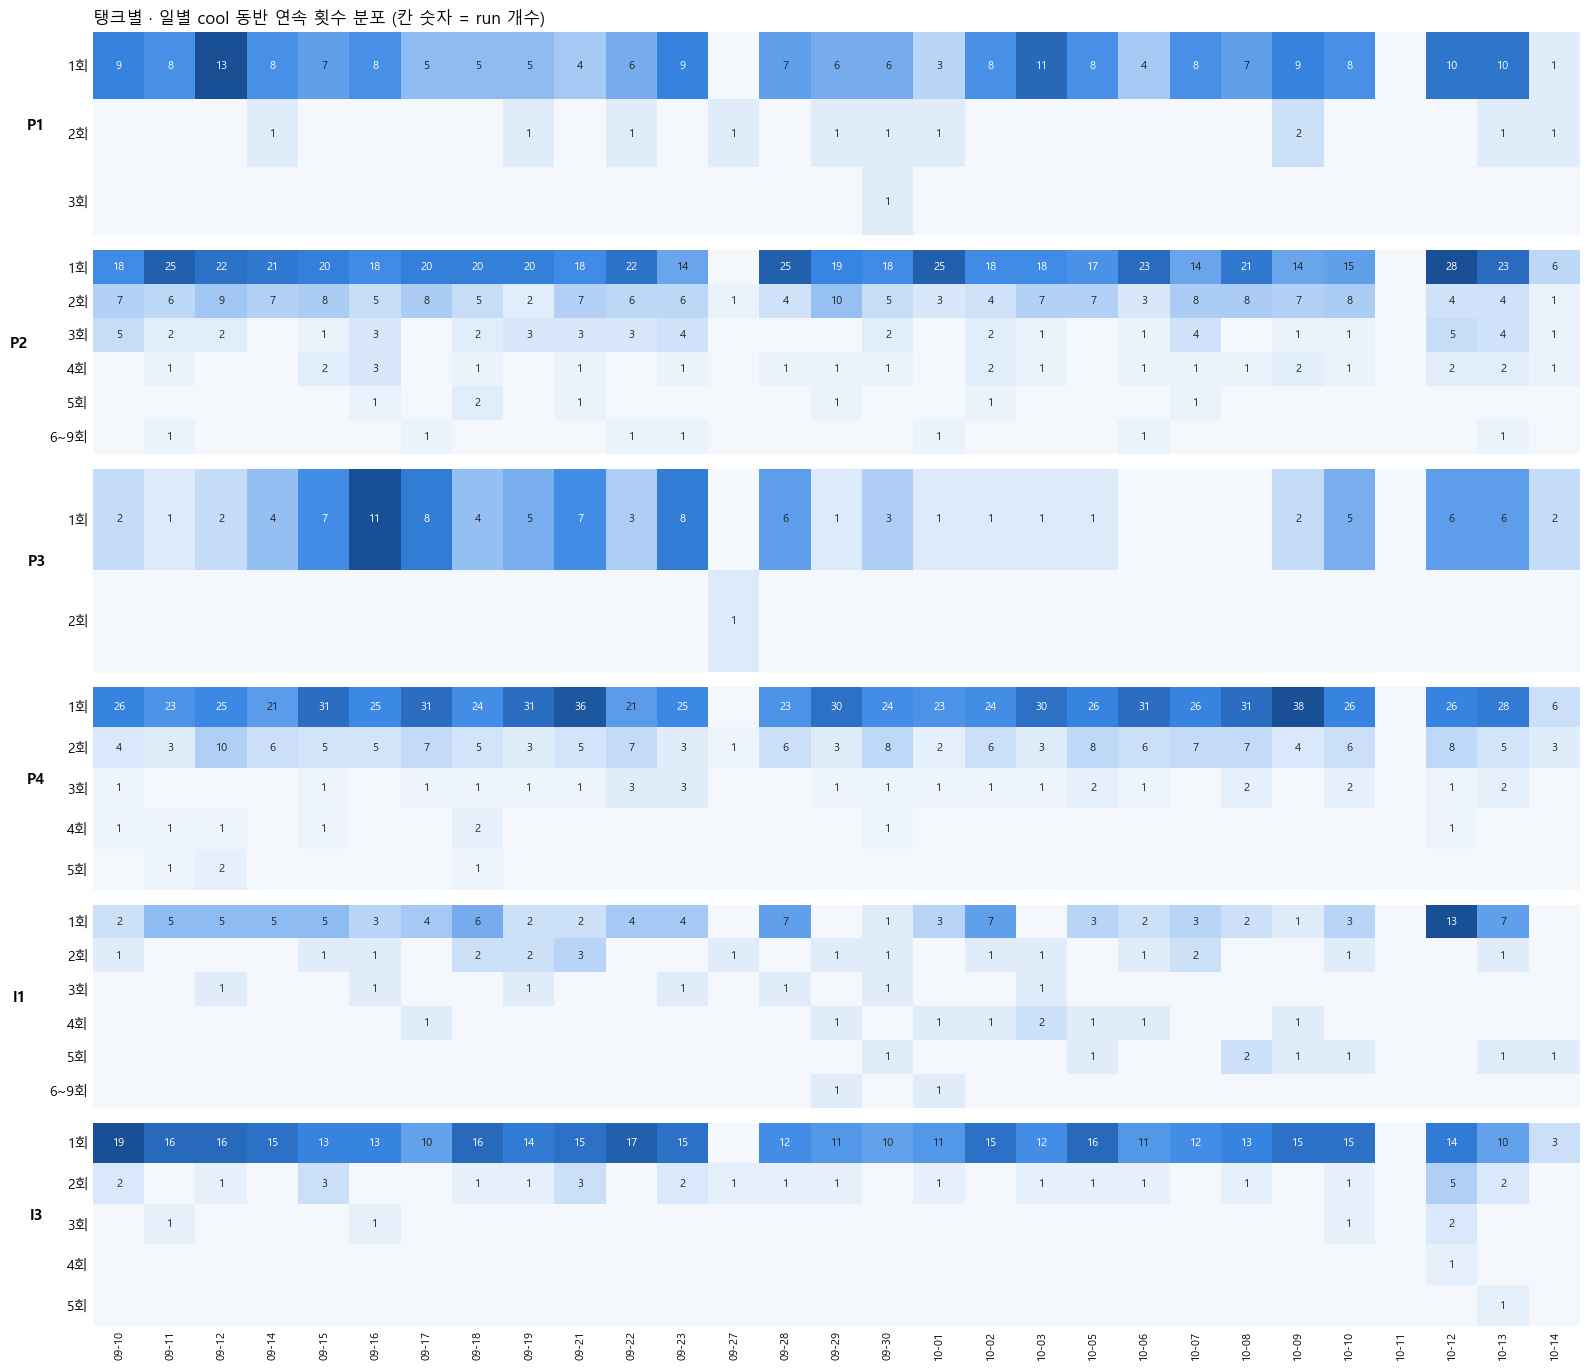

In [10]:
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#9ec5f4", "#3987e5", "#184f95"])
show = ["P1", "P2", "P3", "P4", "I1", "I3"]
all_days = sorted(set().union(*[RES[t]["days"].index for t in show]))

fig, axes = plt.subplots(len(show), 1, figsize=(16, 2.3 * len(show)), sharex=True)
for ax, t in zip(axes, show):
    r = RES[t]["runs"]
    piv = (r.assign(b=r["run_len"].map(bucket))
             .pivot_table(index="b", columns="day", values="run_len", aggfunc="size", fill_value=0)
             .reindex(index=BUCKETS, columns=all_days, fill_value=0))
    piv = piv.loc[:piv.index[(piv.sum(axis=1) > 0).values][-1]]       # 마지막 0 행 이후 생략
    ax.imshow(piv.values, aspect="auto", cmap=SEQ, vmin=0, vmax=max(piv.values.max(), 1))
    for (i, j), v in np.ndenumerate(piv.values):
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8,
                    color="white" if v > 0.6 * piv.values.max() else "#222")
    ax.set_yticks(range(len(piv.index))); ax.set_yticklabels([f"{b}회" for b in piv.index])
    ax.set_ylabel(t, rotation=0, labelpad=22, fontsize=11, fontweight="bold")
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
axes[-1].set_xticks(range(len(all_days)))
axes[-1].set_xticklabels([d.strftime("%m-%d") for d in all_days], rotation=90, fontsize=8)
axes[0].set_title("탱크별 · 일별 cool 동반 연속 횟수 분포 (칸 숫자 = run 개수)", loc="left")
fig.tight_layout(); plt.show()

## 6. P5 · I2 — cool 이 사실상 항상 같이 켜지는 탱크

이 두 탱크는 "cool 동반이 연속 N회" 라는 지표가 다른 탱크와 같은 의미가 아니다.

In [11]:
rows = []
for tank in TANK_LIST:
    exch, cool = SIG[tank]
    c = cool.loc[DAY0:]
    dur = c.index.to_series().diff().shift(-1).dt.total_seconds()
    segs = prep.raw_segments(cool)
    L = pd.Series([(b - a).total_seconds() for a, b in segs])
    rows.append({"탱크": tank, "cool ON 시간비율%": round(100 * dur[c == 1].sum() / dur.sum(), 1),
                 "cool ON 구간 수": len(L), "ON 길이 중앙(초)": round(L.median()),
                 "cycle 중 cool동반%": total.loc[tank, "cool동반%"]})
pd.DataFrame(rows).set_index("탱크")

,cool ON 시간비율%,cool ON 구간 수,ON 길이 중앙(초),cycle 중 cool동반%
탱크,,,,
P1,28.1,230,63,11.2
P2,17.8,1356,12,35.3
P3,14.9,97,179,5.4
P4,17.7,1288,2,19.8
P5,31.2,6036,78,93.3
I1,17.5,253,208,26.3
I2,68.9,41,48053,100.0
I3,23.0,452,194,20.1


In [12]:
# I2: cool 이 6시간 넘게 켜져 있던 구간
exch, cool = SIG["I2"]
cyc = RES["I2"]["cyc"]
long_on = [(a, b) for a, b in prep.raw_segments(cool) if (b - a).total_seconds() > 6 * 3600]
pd.DataFrame([{"ON": f"{a:%m-%d %H:%M}", "OFF": f"{b:%m-%d %H:%M}",
               "시간": round((b - a).total_seconds() / 3600, 1),
               "그 사이 exchanger 사이클": int(((cyc["cycle_start"] >= a) & (cyc["cycle_start"] < b)).sum())}
              for a, b in long_on if b >= DAY0])

,ON,OFF,시간,그 사이 exchanger 사이클
0,09-09 16:03,09-10 00:06,8.0,0
1,09-10 06:17,09-11 00:07,17.8,55
2,09-11 06:20,09-12 00:05,17.7,48
3,09-12 06:24,09-13 00:10,17.8,67
4,09-13 22:40,09-14 09:56,11.3,10
5,09-14 09:58,09-14 23:19,13.3,33
6,09-15 06:24,09-16 00:07,17.7,50
7,09-16 06:26,09-17 00:09,17.7,47
8,09-17 06:22,09-18 00:09,17.8,42
9,09-18 06:21,09-19 00:08,17.8,49


- **I2** — cool 이 **매일 06:20 전후 ~ 다음날 00:05 전후까지 18시간 통으로 켜져 있다.**
  그 사이의 exchanger 사이클은 전부 cool 동반이라, "연속 횟수 = 그날 사이클 수" 가 된다.
  운전 방식이 원래 그런 건지(상시 냉각), 태그 매핑 문제인지는 데이터만으로는 판단 못 한다.
  **현장 확인 필요.** 규칙 ③ (10회 연속) 을 I2 에 그대로 쓰면 매일 아침 10번째 사이클에서 무조건 울린다.
- **P5** — cool 이 짧게(중앙 78초) 켜지지만 **exchanger 사이클마다 거의 매번** 같이 켜진다(93%).
  그날 run 이 4~7개로 쪼개질 뿐이고 cool 이 빠지는 사이클이 드물다. 규칙 ③ 도 매일 울린다.

In [13]:
for t in ["P5", "I2"]:
    print(f"\n===== {t} — 일별 =====")
    r = RES[t]["runs"]
    d = DAILY[t][["사이클", "cool동반", "최장"]].copy()
    d["run 수"] = r.groupby("day").size().values
    d["cool 빠진 사이클"] = d["사이클"] - d["cool동반"]
    print(d.to_string())


===== P5 — 일별 =====
            사이클  cool동반   최장  run 수  cool 빠진 사이클
day                                             
09-10(Thu)  251     233  117      8           18
09-11(Fri)  238     224  112      5           14
09-12(Sat)  237     225  115      5           12
09-14(Mon)  230     212   85      7           18
09-15(Tue)  229     216  108      5           13
09-16(Wed)  240     227   86      6           13
09-17(Thu)  236     223   88      5           13
09-18(Fri)  231     219   82      4           12
09-19(Sat)  240     230  115      4           10
09-21(Mon)  240     224   84      5           16
09-22(Tue)  246     228   90      5           18
09-23(Wed)  236     222  110      5           14
09-27(Sun)    2       2    2      1            0
09-28(Mon)  225     209   55      9           16
09-29(Tue)  234     217   80      7           17
09-30(Wed)  230     215   57      7           15
10-01(Thu)  228     213   53      7           15
10-02(Fri)  221     206   53      7           15

## 7. 정리

| 탱크 | cool 동반% | 1회 | 2회 | 3회 | 4회 | 5회 | 6~9회 | 최장 | 메모 |
|---|---|---|---|---|---|---|---|---|---|
| P1 | 11% | 193 | 11 | 1 | | | | 3 | 거의 단발 |
| P2 | 35% | 522 | 160 | 50 | 26 | 7 | 7 | 8 | 연속이 가장 잦은 '정상 패턴' 탱크 |
| P3 | 5% | 97 | 1 | | | | | 2 | 10/06~08 은 cool 동반 0 |
| P4 | 20% | 711 | 146 | 27 | 8 | 4 | | 5 | |
| P5 | 93% | — | — | — | — | — | — | 117 | cool 이 거의 항상 동반 |
| I1 | 26% | 99 | 20 | 7 | 9 | 8 | 2 | 9 | **9/29 부터 동반 비율·연속 길이 증가** |
| I2 | 100% | — | — | — | — | — | — | 67 | 생산 중 cool 상시 ON |
| I3 | 20% | 359 | 29 | 5 | 1 | 1 | | 5 | 10/12 에 2~4회 연속이 몰림 |

(위 수치는 4장 표에서 옮겨 적은 것. 셀 실행 결과가 원본이다.)

**I1 9/29 이후 변화** — 9/10~9/28 은 하루 사이클 34~45개 중 cool 동반 4~10개, 최장 1~4회였다.
9/29~10/10 은 사이클이 26~36개로 줄고 cool 동반은 7~15개로 늘었다. 최장 5회 이상인 날이
9/28 까지는 0일이었는데 9/29~10/10 은 11일 중 7일(최장 9회, 9/29).
10/12(월) 는 13개가 전부 단발로 돌아왔다가 10/13 에 다시 5회 연속이 나왔다.

**규칙 ③ (10회 연속) 관점** — P5 · I2 를 빼면 이 기간 전체 최장은 I1 의 9회. 10회는 한 번도 없다.
P5 · I2 는 매일 넘는다. 탱크별로 다른 기준이 필요하다.